**Step 1 — Import libraries and load the dataset**

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)
from sklearn.inspection import permutation_importance

# Load dataset
df = pd.read_csv("student_dataset_nb.csv")

# Display first five rows
display(df.head())


,Student_ID,Study_Hours,Attendance,Sleep_Quality,Pass_Exam
0,S01,High,High,Good,Yes
1,S02,High,Low,Good,Yes
2,S03,Low,High,Poor,No
3,S04,Medium,High,Good,Yes
4,S05,Low,Low,Good,No


In [2]:
df = pd.read_csv("student_dataset_nb.csv")
print(df.head())

  Student_ID Study_Hours Attendance Sleep_Quality Pass_Exam
0        S01        High       High          Good       Yes
1        S02        High        Low          Good       Yes
2        S03         Low       High          Poor        No
3        S04      Medium       High          Good       Yes
4        S05         Low        Low          Good        No


In [3]:
df.head()

,Student_ID,Study_Hours,Attendance,Sleep_Quality,Pass_Exam
0,S01,High,High,Good,Yes
1,S02,High,Low,Good,Yes
2,S03,Low,High,Poor,No
3,S04,Medium,High,Good,Yes
4,S05,Low,Low,Good,No


**Step 2 — Understand the data**

In [4]:
print("Dataset shape:", df.shape)

Dataset shape: (20, 5)


In [5]:
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['Student_ID', 'Study_Hours', 'Attendance', 'Sleep_Quality', 'Pass_Exam']


In [6]:
print("\nData types:")
df.dtypes


Data types:


Student_ID       str
Study_Hours      str
Attendance       str
Sleep_Quality    str
Pass_Exam        str
dtype: object

In [7]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
Student_ID       0
Study_Hours      0
Attendance       0
Sleep_Quality    0
Pass_Exam        0
dtype: int64


In [8]:
print("\nDuplicate rows:")
print(df.duplicated().sum())


Duplicate rows:
0


In [9]:
print("\nDescriptive statistics")
print(df.describe(include="all").T)


Descriptive statistics
              count unique   top freq
Student_ID       20     20   S01    1
Study_Hours      20      3  High    7
Attendance       20      3  High    9
Sleep_Quality    20      2  Good   11
Pass_Exam        20      2   Yes   11


In [10]:
print("\nNumerical columns:")
print(df.select_dtypes(include=np.number).columns.tolist())


Numerical columns:
[]


In [11]:
print("\nCategorical columns:")
print(df.select_dtypes(exclude=np.number).columns.tolist())


Categorical columns:
['Student_ID', 'Study_Hours', 'Attendance', 'Sleep_Quality', 'Pass_Exam']


**Inspect the target**

In [12]:
TARGET = "Pass_Exam"

if TARGET not in df.columns:
    raise ValueError("Pass_Exam was not found. Inspect the columns and select a suitable target.")
print("Unique target values:", df[TARGET].nunique())
print("\nTarget distribution:")
print(df[TARGET].value_counts(dropna=False))
print("\nTarget proportion:")
print(df[TARGET].value_counts(normalize=True, dropna=False))

Unique target values: 2

Target distribution:
Pass_Exam
Yes    11
No      9
Name: count, dtype: int64

Target proportion:
Pass_Exam
Yes    0.55
No     0.45
Name: proportion, dtype: float64


**Step 3 — Exploratory Data Analysis (EDA)**

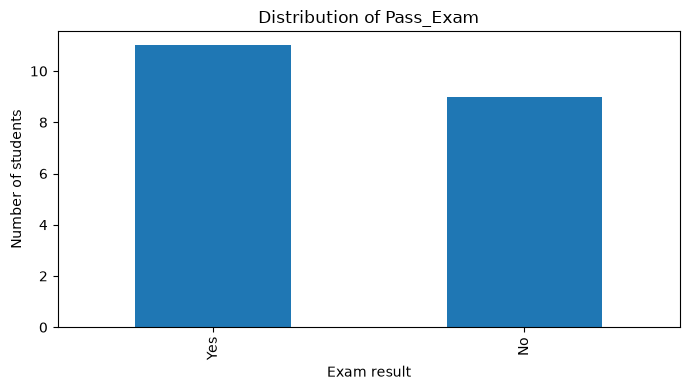

In [24]:

# Plot distributions of up to two numerical variables
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

for col in numeric_cols[:2]:
    plt.figure(figsize=(7, 4))
    df[col].dropna().hist(bins=20)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

# Plot target distribution
plt.figure(figsize=(7, 4))
df[TARGET].value_counts(dropna=False).plot(kind="bar")
plt.title("Distribution of Pass_Exam")
plt.xlabel("Exam result")
plt.ylabel("Number of students")
plt.tight_layout()
plt.show()

# Plot relationships between numerical features and target
for col in [c for c in numeric_cols if c != TARGET][:2]:
    df.boxplot(column=col, by=TARGET, figsize=(7, 4))
    plt.title(f"{col} by exam result")
    plt.suptitle("")
    plt.tight_layout()
    plt.show()

# Correlation heatmap
if len(numeric_cols) >= 2:
    corr = df[numeric_cols].corr()
    plt.figure(figsize=(9, 6))
    plt.imshow(corr, vmin=-1, vmax=1, aspect="auto")
    plt.colorbar(label="Correlation")
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
    plt.yticks(range(len(corr.columns)), corr.columns)
    plt.title("Numerical Feature Correlations")
    plt.tight_layout()
    plt.show()


**Step 4 — Clean the data and define X and y**

In [26]:
# Identify ID columns
student_id = [
    c for c in df.columns
    if c.lower() in ["id", "student_id", "studentid", "unnamed: 0"]
    or c.lower().endswith("_id")
]

# Display the ID columns found
print("Identifier columns removed:", student_id)

# Separate features (X) and target (y)
X = df.drop(columns=[TARGET] + student_id)
y = df[TARGET]

Identifier columns removed: ['Student_ID']


**Step 5 — Train/test split**

In [27]:

# Check whether the target is categorical
is_classification = (
    not pd.api.types.is_numeric_dtype(y)
    or y.nunique() <= 15
)

# Stratification preserves class proportions when feasible
stratify_target = (
    y if is_classification and y.value_counts().min() >= 2
    else None
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=stratify_target
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 16
Testing rows: 4


**Step 6 — Preprocess numerical and categorical features**

In [37]:
numeric_features = df.select_dtypes(include=np.number).columns.tolist()
categoric_features = df.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categoric_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequency")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preproccessor = ColumnTransformer([
    ("numerical", numeric_pipeline, numeric_features),
    ("categorical", categoric_pipeline, categoric_features)
])

print("Numerical Features:", numeric_features)
print("Categorical_features:", categoric_features)

Numerical Features: []
Categorical_features: ['Student_ID', 'Study_Hours', 'Attendance', 'Sleep_Quality', 'Pass_Exam']


**Step 7 — Build two classification models**

In [38]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

# Identify column types
numeric_features = df.select_dtypes(include=["number"]).columns.tolist()
categorical_features = df.select_dtypes(exclude=["number"]).columns.tolist()

# Create numerical transformer
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Create categorical transformer
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Create the preprocessor
transformers = []

if numeric_features:
    transformers.append(("num", numeric_transformer, numeric_features))

if categorical_features:
    transformers.append(("cat", categorical_transformer, categorical_features))

preprocessor = ColumnTransformer(transformers=transformers)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify columns using the current X dataframe
numeric_features = df.select_dtypes(include=["number"]).columns.tolist()

categorical_features = df.select_dtypes(include=np.number).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Build the preprocessor
transformers = []

if numeric_features:
    transformers.append(
        ("num", numeric_transformer, numeric_features)
    )

if categorical_features:
    transformers.append(
        ("cat", categorical_transformer, categorical_features)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

print("Preprocessor updated successfully!")
print("Numerical columns:", numeric_features)
print("Categorical columns:", categorical_features)

Preprocessor updated successfully!
Numerical columns: []
Categorical columns: []


In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

model1 = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

model2 = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

print("Both model pipelines created successfully!")

Both model pipelines created successfully!


In [49]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# 1. Define the target and remove identifier columns
TARGET = "Pass_Exam"

X = df.drop(
    columns=[TARGET, "Student_ID"],
    errors="ignore"
)
y = df[TARGET]

# 2. Create fresh training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Identify columns from the current training data
numeric_features = X_train.select_dtypes(include=["n"]).columns.tolist()

categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

# 4. Build fresh preprocessing pipelines
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

transformers = []

if numeric_features:
    transformers.append(
        ("num", numeric_transformer, numeric_features)
    )

if categorical_features:
    transformers.append(
        ("cat", categorical_transformer, categorical_features)
    )

preprocessor = ColumnTransformer(transformers=transformers)

# 5. Rebuild both models using the fresh preprocessor
model1 = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

model2 = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

# 6. Train both models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)

print("Both models trained successfully!")
print("Training data shape:", X_train.shape)
print("Target column:", TARGET)

Both models trained successfully!
Training data shape: (16, 3)
Target column: Pass_Exam


In [46]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Generate predictions
y_pred1 = model1.predict(X_test)
y_pred2 = model2.predict(X_test)

# Evaluate Logistic Regression
print("=== Logistic Regression ===")
print("Accuracy:", accuracy_score(y_test, y_pred1))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred1))
print(classification_report(y_test, y_pred1, zero_division=0))

# Evaluate Random Forest
print("\n=== Random Forest ===")
print("Accuracy:", accuracy_score(y_test, y_pred2))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred2))
print(classification_report(y_test, y_pred2, zero_division=0))

=== Logistic Regression ===
Accuracy: 0.75
Confusion Matrix:
[[1 1]
 [0 2]]
              precision    recall  f1-score   support

          No       1.00      0.50      0.67         2
         Yes       0.67      1.00      0.80         2

    accuracy                           0.75         4
   macro avg       0.83      0.75      0.73         4
weighted avg       0.83      0.75      0.73         4


=== Random Forest ===
Accuracy: 0.75
Confusion Matrix:
[[1 1]
 [0 2]]
              precision    recall  f1-score   support

          No       1.00      0.50      0.67         2
         Yes       0.67      1.00      0.80         2

    accuracy                           0.75         4
   macro avg       0.83      0.75      0.73         4
weighted avg       0.83      0.75      0.73         4



**Step 8 — Evaluate and compare models**

In [47]:

models = {
    "Logistic Regression": model1,
    "Random Forest": model2
}

results = []
predictions = {}

for name, model in models.items():
    pred = model.predict(X_test)
    predictions[name] = pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision_weighted": precision_score(
            y_test, pred, average="weighted", zero_division=0
        ),
        "Recall_weighted": recall_score(
            y_test, pred, average="weighted", zero_division=0
        ),
        "F1_weighted": f1_score(
            y_test, pred, average="weighted", zero_division=0
        )
    })

comparison = pd.DataFrame(results)
display(comparison.round(4))


,Model,Accuracy,Precision_weighted,Recall_weighted,F1_weighted
0,Logistic Regression,0.75,0.8333,0.75,0.7333
1,Random Forest,0.75,0.8333,0.75,0.7333


In [48]:

for name, model in models.items():
    print(f"\n{name}")
    print(classification_report(
        y_test,
        predictions[name],
        zero_division=0
    ))

    cm = confusion_matrix(y_test, predictions[name])
    print("Confusion matrix:\n", cm)



Logistic Regression
              precision    recall  f1-score   support

          No       1.00      0.50      0.67         2
         Yes       0.67      1.00      0.80         2

    accuracy                           0.75         4
   macro avg       0.83      0.75      0.73         4
weighted avg       0.83      0.75      0.73         4

Confusion matrix:
 [[1 1]
 [0 2]]

Random Forest
              precision    recall  f1-score   support

          No       1.00      0.50      0.67         2
         Yes       0.67      1.00      0.80         2

    accuracy                           0.75         4
   macro avg       0.83      0.75      0.73         4
weighted avg       0.83      0.75      0.73         4

Confusion matrix:
 [[1 1]
 [0 2]]


**Step 9 — Error analysis**

In [94]:

best_name = comparison.sort_values(
    "F1_weighted", ascending=False
).iloc[0]["Model"]

best_model = models[best_name]
best_predictions = predictions[best_name]

errors = X_test.copy()
errors["Actual"] = y_test
errors["Predicted"] = best_predictions
errors["Correct"] = errors["Actual"] == errors["Predicted"]

print("Selected model:", best_name)
print("\nIncorrect predictions:")
display(errors[~errors["Correct"]].head(20))


Selected model: Logistic Regression

Incorrect predictions:


,Study_Hours,Attendance,Sleep_Quality,Actual,Predicted,Correct
15,Medium,Low,Good,No,Yes,False


**Step 10 — Feature importance**

,Feature,Importance
0,Study_Hours,0.32
1,Attendance,0.00
2,Sleep_Quality,0.00


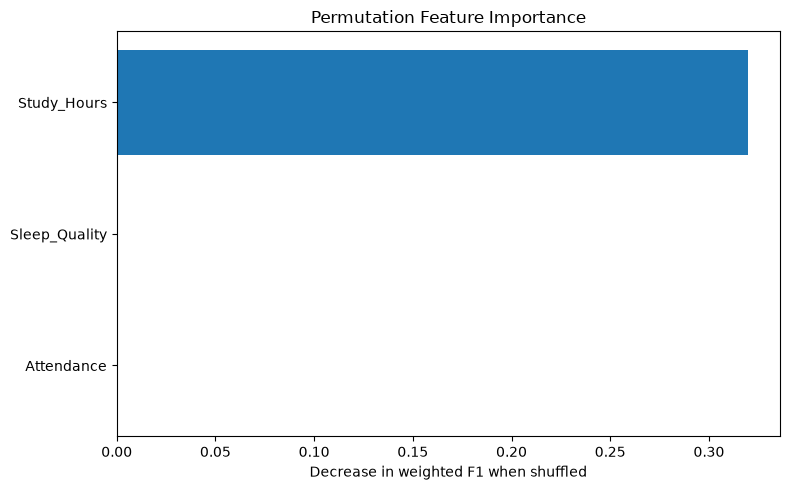

In [95]:

importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="f1_weighted",
    n_repeats=5,
    random_state=42
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(8, 5))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Decrease in weighted F1 when shuffled")
plt.title("Permutation Feature Importance")
plt.tight_layout()
plt.show()


**Step 11 — Optional hyperparameter tuning**

In [96]:

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_leaf": [1, 2, 4]
}

search = GridSearchCV(
    estimator=model2,
    param_grid=param_grid,
    scoring="f1_weighted",
    cv=3,
    n_jobs=-1
)

search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print("Best cross-validation F1:", search.best_score_)

tuned_predictions = search.best_estimator_.predict(X_test)

print(
    "Tuned test F1:",
    f1_score(y_test, tuned_predictions, average="weighted", zero_division=0)
)


Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
Best cross-validation F1: 0.9333333333333332
Tuned test F1: 0.7333333333333334


In [ ]:
# Use this structure for the written report, filling in the findings and metrics from your notebook.
# 1. Problem definition: Predict students' exam outcomes from available student information.
# 2. Target variable: Pass_Exam, if confirmed appropriate after inspecting its values and meaning.
# 3. Data quality: Report missing values, duplicates, data types, and cleaning decisions.
# 4. EDA findings: List three genuine findings from your visualizations.
# 5. Models: Logistic Regression and Random Forest, if the target is categorical.
# 6. Evaluation: Insert the actual accuracy, precision, recall, and F1 results; explain the trade-offs.
# 7. Error analysis: Describe patterns observed in the incorrect predictions.
# 8. Final model: Select the model that best meets the problem's objective, supported by test results.
# 9. Limitations: Consider sample size, class imbalance, missing features, leakage risk, and generalizability.
# 10. Next steps: Improve data quality, investigate leakage, tune the model, and validate on new data.